# Demo 4｜实验质量诊断与报告助手

目标是把可自动化的质量诊断和报告草稿标准化。此处的“助手”是确定性规则与结构化文本生成，不调用外部大模型；每个结论可回溯到计算结果。

**数据声明**：以下均为固定随机种子生成的模拟数据，不代表真实滴滴业务效果。图中的英文标签用于避免本地中文字体依赖。

## 实验登记、日志与指标字典

模拟登记、分流、曝光、结果表。故意让实验组曝光日志少 6%，用于演示异常识别。不能把未曝光样本从 ITT 主分析中删除。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(20261028)
registry={'experiment_id':'demo-exp-001','allocation':0.5,'unit':'user','primary':'orders','guardrail':'cancel','query_version':'sim-v1','owner':'demo'}
metric_dict={'orders':'7-day completed orders per assigned user','cancel':'7-day cancellation indicator'}
n=4000;assigned=rng.binomial(1,.5,n);pre=rng.poisson(2,n)
exposure=rng.binomial(1,np.where(assigned==1,.90,.96))
df=pd.DataFrame({'user_id':np.arange(n),'arm':assigned,'exposed':exposure,'pre_orders':pre,'orders':rng.poisson(1.4+.3*pre+.12*assigned),'cancel':rng.binomial(1,.12-.003*assigned,n)})
print(registry,metric_dict);print(df.head())

{'experiment_id': 'demo-exp-001', 'allocation': 0.5, 'unit': 'user', 'primary': 'orders', 'guardrail': 'cancel', 'query_version': 'sim-v1', 'owner': 'demo'} {'orders': '7-day completed orders per assigned user', 'cancel': '7-day cancellation indicator'}
   user_id  arm  exposed  pre_orders  orders  cancel
0        0    0        1           2       2       0
1        1    0        1           5       2       0
2        2    1        1           6       2       0
3        3    0        1           5       3       0
4        4    1        1           0       1       1


## 自动诊断与阻断规则

SRM 阈值 p<0.001；组间曝光率差异超过 3 个百分点记为异常；基线差异用标准化均差 |SMD|>0.1。阈值是演示用规则，真实团队应按误报成本制定。

          check     value   pass
0           SRM  0.635256   True
1  Exposure gap  0.055113  False
2  Baseline SMD  0.002294   True


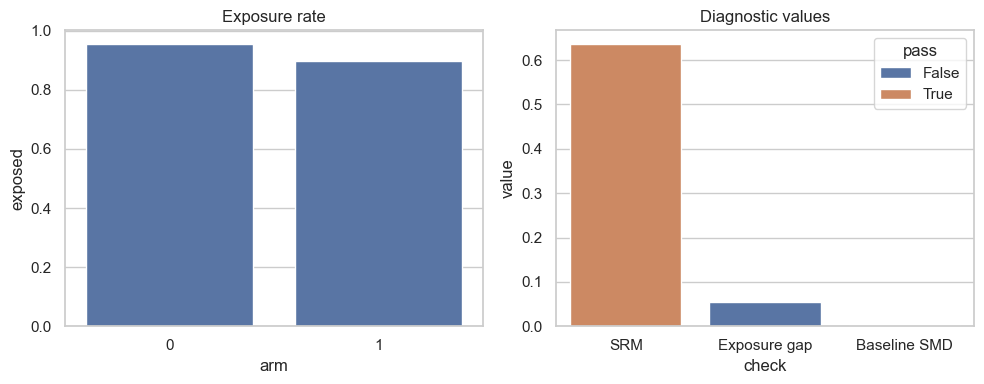

In [2]:
count=df.arm.value_counts().sort_index();srm_p=stats.chisquare(count,[n/2,n/2]).pvalue
ex=df.groupby('arm').exposed.mean();base=df.groupby('arm').pre_orders.mean();pooled=np.sqrt(df.groupby('arm').pre_orders.var().mean());smd=(base[1]-base[0])/pooled
checks=pd.DataFrame([['SRM',srm_p,srm_p>=.001],['Exposure gap',abs(ex[1]-ex[0]),abs(ex[1]-ex[0])<=.03],['Baseline SMD',abs(smd),abs(smd)<=.1]],columns=['check','value','pass'])
print(checks)
fig,ax=plt.subplots(1,2,figsize=(10,4));sns.barplot(data=df,x='arm',y='exposed',errorbar=None,ax=ax[0]);ax[0].set_title('Exposure rate');sns.barplot(data=checks,x='check',y='value',hue='pass',dodge=False,ax=ax[1]);ax[1].set_title('Diagnostic values');plt.tight_layout();plt.show()

## 效果、样本路径与报告草稿

ITT 在所有已分配用户上计算。曝光差异可能反映日志缺失或真实触达差异，必须人工定位；诊断未通过时报告草稿标记“待复核”。

   metric    effect       low      high
0  orders  0.071369 -0.021543  0.164281
1  cancel -0.006103 -0.026708  0.014502
     assigned  exposed
arm                   
0        2015     1921
1        1985     1783


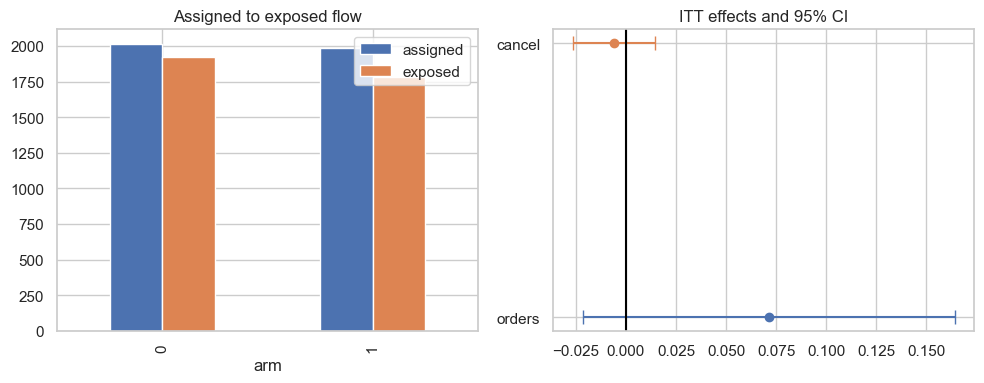

实验 demo-exp-001｜查询版本 sim-v1
数据来源：本 notebook 固定随机种子模拟；分析单元：user。
质量状态：待复核；异常项：['Exposure gap']。
主指标 ITT：0.071，95% CI [-0.022, 0.164]。
护栏效果：-0.006。
人工复核：曝光差异成因、分流与埋点一致性、干扰、实际成本和上线阈值。


In [3]:
def comparison(col):
 x=df.loc[df.arm==1,col];y=df.loc[df.arm==0,col];d=x.mean()-y.mean();se=np.sqrt(x.var(ddof=1)/len(x)+y.var(ddof=1)/len(y));return d,d-1.96*se,d+1.96*se
metrics=pd.DataFrame([('orders',*comparison('orders')),('cancel',*comparison('cancel'))],columns=['metric','effect','low','high']);print(metrics)
flow=df.groupby('arm').agg(assigned=('user_id','size'),exposed=('exposed','sum'));print(flow)
fig,ax=plt.subplots(1,2,figsize=(10,4));flow.plot(kind='bar',ax=ax[0]);ax[0].set_title('Assigned to exposed flow')
for i,row in metrics.iterrows():ax[1].errorbar(row.effect,i,xerr=[[row.effect-row.low],[row.high-row.effect]],fmt='o',capsize=5)
ax[1].axvline(0,color='black');ax[1].set_yticks(range(len(metrics)),metrics.metric);ax[1].set_title('ITT effects and 95% CI');plt.tight_layout();plt.show()
status='待复核' if not checks['pass'].all() else '质量检查通过'
report=f'''实验 {registry['experiment_id']}｜查询版本 {registry['query_version']}
数据来源：本 notebook 固定随机种子模拟；分析单元：{registry['unit']}。
质量状态：{status}；异常项：{checks.loc[~checks['pass'],'check'].tolist()}。
主指标 ITT：{metrics.loc[0,'effect']:.3f}，95% CI [{metrics.loc[0,'low']:.3f}, {metrics.loc[0,'high']:.3f}]。
护栏效果：{metrics.loc[1,'effect']:.3f}。
人工复核：曝光差异成因、分流与埋点一致性、干扰、实际成本和上线阈值。'''
print(report)

## 模拟结果解读与决策摘要

- SRM p≈0.635，基线 SMD≈0.002，均通过演示规则；实验组与对照组曝光率相差约 **5.5 个百分点**，超过预设 3 个百分点阈值，因此报告标记**待复核**。
- 全分配用户的完单 ITT 约 **+0.071**，95% 区间约 **[-0.022,+0.164]**；模拟样本尚不足以排除零效应或小幅负效应。取消率效果约 -0.006，区间也跨零。
- 下一步应先区分“真实曝光不足”和“曝光日志丢失”，核对实验组客户端/服务端日志链路。不能通过只保留曝光用户来修复 ITT。
- 结构化报告应保留实验 ID、查询版本、指标口径和审核人。自动生成的文字只复述计算证据，不能替代识别假设与上线决策审查。


## 实证分析接入

当前目录没有可用于此案例的真实数据，故不把模拟结论解释为实际业务结论。接入真实数据时：①取得脱敏且获授权的数据；②核对数据字典、随机化/触达机制和时间窗；③用真实数据替换模拟数据生成单元；④重跑质量诊断与敏感性分析；⑤在审阅关键识别假设后更新决策摘要。